# Overall Architecture

Goal: Predict daily change in 5-day volatility of the S&P500.

Numeric features are input into an LSTM. Text is input into a transformer. The output vectors of both are concatenated and then input into a FFNN to learned the optimal weighting of Tweets and numeric data. We are not optimizing individual modalities in this tri-modal architecture, but rather optimizing the weights and biases of the coupled system as a whole set. 

# Data Preparation and Verification

CSV files have been adjusted in Excel to only include dates from November 8 2016 (presidential election) to January 8 2021 (near the last date of Trump's 1st term). The files are in descending chronological order, with the most recent data appearing at the top. 



In [106]:
import pandas as pd

snp_df = pd.read_csv(r"C:\Users\email\Downloads\SNP500 - Copy.csv")
snp_df["Date"] = pd.to_datetime(
    snp_df["Date"],
    format="%m/%d/%Y"
)

snp_df = snp_df.rename(columns={"Close/Last": "Close"})
snp_df = snp_df.iloc[::-1].reset_index(drop=True)

import numpy as np

# Log returns
snp_df['log_return'] = np.log(snp_df['Close'] / snp_df['Close'].shift(1))

# 5-day rolling volatility of log_return
snp_df['5d_vol'] = snp_df['log_return'].rolling(window=5).std()

# Daily change in volatility
snp_df['delta_5d_vol'] = snp_df['5d_vol'].diff()

snp_df = snp_df.drop(columns=['Close', 'Volume', 'Open', 'High', 'Low'])
print(snp_df.tail())

           Date  log_return    5d_vol  delta_5d_vol
1044 2021-01-04   -0.013708  0.008549      0.004623
1045 2021-01-05    0.006864  0.008145     -0.000405
1046 2021-01-06    0.005961  0.008543      0.000399
1047 2021-01-07    0.014748  0.010512      0.001969
1048 2021-01-08    0.005682  0.010535      0.000022


The market opens at 9:30 a.m. ET closes at 4 p.m. ET. We want to predict what the Tweets' impact is on S&P500 price movement, thus we want create a market adjusted date colum in *tweets_df* called *Mkt_Adj_Date* that aligns a Tweet with the next trading day’s market if they occur after market close, and otherwise with the same day’s market.

The 1st Tweet is in this link

https://x.com/realDonaldTrump/status/1347569870578266115

I am in GMT+8 and the Tweet is listed as being on 11:44 p.m. on Jan 8 2021, but in the data it is 3:44 p.m. on Jan 8 2021. This is a date where Daylight Saving is off. Thus our data is probably registering time in UTC. To confirm this, we shall inspect the following Tweet during a date where Daylight Saving is on. 

https://x.com/realDonaldTrump/status/1265985660898459655?ref_src=twsrc%5Etfw%7Ctwcamp%5Etweetembed%7Ctwterm%5E1265985660898459655%7Ctwgr%5Ecc9f8c2c95223b6a7b3ecc15d75baddf6e2e243f%7Ctwcon%5Es1_&ref_url=https%3A%2F%2Ffinancialpost.com%2Ftechnology%2Fbig-day-for-fairness-trump-to-sign-executive-order-targeting-political-bias-at-twitter-facebook

It is timestamped for me as 8:37 p.m. on May 28 2020, but is reflected as 12:37 p.m. on May 28 2020. This confirms that the data presents time in UTC and is agnostic to Daylight Saving. 

An additional *Date_ET* column is created to transform the dates into ET. But we should note that ET can be UTC-4 or UTC-5 depending on whether Daylight Saving is on or off respectively. Pandas will handle this variation automatically. The based on *Date_ET* we create a *Mkt_Adj_Date* for alignment with trading times. 

In [107]:
tweets_df = pd.read_csv(r"C:\Users\email\Downloads\tweets - Copy.csv")

# Ensure 'date' is datetime and timezone-aware (UTC)
tweets_df["date"] = pd.to_datetime(
    tweets_df["date"],
    format="%d/%m/%Y %H:%M"
)

# Convert UTC to Eastern Time 
tweets_df["date"] = pd.to_datetime(tweets_df["date"], utc=True)
tweets_df["Date_ET"] = tweets_df["date"].dt.tz_convert("America/New_York")

# Create market-adjusted date
tweets_df["Mkt_Adj_Date"] = tweets_df["Date_ET"].apply(
    lambda x: x.date() if x.hour < 16 else (x + pd.Timedelta(days=1)).date()
)

# Reverse order of rows in tweets_df, so it becomes least to most recent from top to bottom. This is important because when I aggregate all Tweets per market adjusted
# day I want the Tweets to respect temporal order such that for a given day, the 1st Tweet of the day comes first, 2nd of the day comes 2nd and so on. 
tweets_df = tweets_df.iloc[::-1].reset_index(drop=True)
print(tweets_df.head())

                   id  \
0  795779987152523264   
1  795781945607278592   
2  795782371895349250   
3  795834203430645760   
4  795845126744604673   

                                                                                                                                             text  \
0  Thank you Pennsylvania! Going to New Hampshire now and on to Michigan. Watch PA rally here: https://t.co/d29DLINGst... https://t.co/zcH9crFIKM   
1     Today in Florida, I pledged to stand with the people of Cuba and Venezuela in their fight against oppression- cont: https://t.co/8eELqk2wUw   
2                                                                  Big news to share in New Hampshire tonight! Polls looking great! See you soon.   
3        Unbelievable evening in New Hampshire - THANK YOU! Flying to Grand Rapids, Michigan now. Watch NH rally here:... https://t.co/hP88anrfgk   
4           RT @detroitnews: .@IvankaTrump in Michigan: ‘This is your movement’ https://t.co/0Sa7huoOP1 

Create a new dataframe *agg_tweets_df* that combines all Tweets in a market adjusted date into a single meta-Tweet. Combine all engagement metrics as well. Note the output of the print statement. The Tweet text is appearing in the correct order with the most recent Tweet first in aggregation. This is necessary for Tweet temporarlity. 

In [108]:
agg_tweets_df = (
    tweets_df
    .groupby("Mkt_Adj_Date", as_index=False)["text"]
    .agg(lambda x: " ".join(x))
)

pd.set_option('display.max_colwidth', None)
tweets_df["Mkt_Adj_Date"] = pd.to_datetime(tweets_df["Mkt_Adj_Date"])
print(agg_tweets_df.head())

  Mkt_Adj_Date  \
0   2016-11-08   
1   2016-11-09   
2   2016-11-10   
3   2016-11-11   
4   2016-11-12   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                           

Then combine *agg_tweets_df* and *snp_df*. For days where Trump Tweets but there is no price data, like a weekend, the Tweets of the price-absent days gets moved over to the next closest trading day. On days where there is price movement, but no Tweets, simply leave it blank. 

In [109]:
agg_tweets_df["Mkt_Adj_Date"] = pd.to_datetime(agg_tweets_df["Mkt_Adj_Date"])
snp_df = snp_df.sort_values('Date')
agg_tweets_df = agg_tweets_df.sort_values('Mkt_Adj_Date')


merged = pd.merge_asof(
    agg_tweets_df, 
    snp_df[['Date']], 
    left_on='Mkt_Adj_Date', 
    right_on='Date', 
    direction='forward'
)

# Aggregate all tweets for each snp_df Date
text_per_date = merged.groupby('Date')['text'].apply(lambda x: ' '.join(x)).reset_index()

# Merge the aggregated text back to snp_df
merged_df = snp_df.merge(text_per_date, on='Date', how='left')
merged_df = merged_df.set_index('Date')
print(merged_df.tail(7))

# Creating lagged features 
cols = ["log_return", "5d_vol"]
max_lag = 10

for col in cols:
    for lag in range(1, max_lag + 1):
        merged_df[f"{col}_lag_{lag}"] = merged_df[col].shift(lag)


merged_df = merged_df.dropna().reset_index(drop=True)
merged_df.columns

            log_return    5d_vol  delta_5d_vol  \
Date                                             
2020-12-30    0.001426  0.003928     -0.000448   
2020-12-31    0.005068  0.003926     -0.000001   
2021-01-04   -0.013708  0.008549      0.004623   
2021-01-05    0.006864  0.008145     -0.000405   
2021-01-06    0.005961  0.008543      0.000399   
2021-01-07    0.014748  0.010512      0.001969   
2021-01-08    0.005682  0.010535      0.000022   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                     

Index(['log_return', '5d_vol', 'delta_5d_vol', 'text', 'log_return_lag_1',
       'log_return_lag_2', 'log_return_lag_3', 'log_return_lag_4',
       'log_return_lag_5', 'log_return_lag_6', 'log_return_lag_7',
       'log_return_lag_8', 'log_return_lag_9', 'log_return_lag_10',
       '5d_vol_lag_1', '5d_vol_lag_2', '5d_vol_lag_3', '5d_vol_lag_4',
       '5d_vol_lag_5', '5d_vol_lag_6', '5d_vol_lag_7', '5d_vol_lag_8',
       '5d_vol_lag_9', '5d_vol_lag_10'],
      dtype='object')

We want to perform bytepair encoding to prepare text for transformer input. We need to examine the corpus before determining the *vocab_size* paramter. We need to determine many of the most used words account for 95% of all words in the corpus. That value is 29 529 which forms the upper limit of *vocab_size*. This is a sanity check. By Zipf’s law, a small number of high-frequency subwords will almost always account for most token occurrences. 

Total words: 621231
Unique words: 60572
Top N words covering 95% of all words: 29511


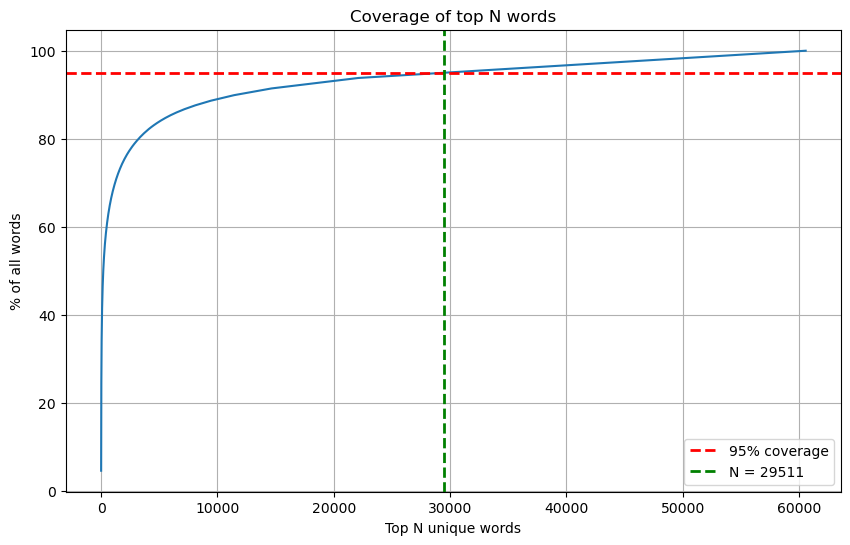

In [110]:
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

texts = merged_df["text"].astype(str).tolist()
word_counts = Counter(w.lower() for t in texts for w in t.split())

total_words = sum(word_counts.values())
unique_words = len(word_counts)

# Sort word counts
sorted_counts = [count for word, count in word_counts.most_common()]
cumulative_counts = np.cumsum(sorted_counts)
total_tokens = sum(sorted_counts)

# Compute coverage
coverage_percent = cumulative_counts / total_tokens * 100
top_N = np.arange(1, len(sorted_counts) + 1)

# Now this works
top_N_95 = np.argmax(coverage_percent >= 95) + 1

print("Total words:", total_words)
print("Unique words:", unique_words)
print("Top N words covering 95% of all words:", top_N_95)

# Plot
plt.figure(figsize=(10,6))
plt.plot(top_N, coverage_percent)
plt.xlabel("Top N unique words")
plt.ylabel("% of all words")
plt.title("Coverage of top N words")
plt.grid(True)

plt.axhline(y=95, linestyle='--', color='red', linewidth=2, label='95% coverage')
plt.axvline(x=top_N_95, linestyle='--', color='green', linewidth=2, label=f'N = {top_N_95}')

plt.legend()
plt.show()


*vocab_size* should be treated as a trade-off parameter several candidates evaluated e.g. 8000, 12 000, 16 000 etc. Ideally we want the smallest *vocab_size* that does not significantly increase sequence length or fragment frequent terms.

We will train a BPE tokenizer on a large *vocab_size* parameter using the above 25 757 as a guideline, trialling a value of 8000. Tokenzier training should only take place on the training set. We will prepare the data like so.

In [111]:
from sklearn.preprocessing import StandardScaler
import sentencepiece as spm
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
import copy
import numpy as np


n = len(merged_df)
train_end = int(0.7 * n)
val_end = int(0.85 * n)

train_df = merged_df.iloc[:train_end]
val_df = merged_df.iloc[train_end:val_end]
test_df = merged_df.iloc[val_end:]

y_train = train_df['delta_5d_vol']
y_val = val_df['delta_5d_vol']
y_test = test_df['delta_5d_vol']
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32)
y_val_tensor   = torch.tensor(y_val.values, dtype=torch.float32)
y_test_tensor  = torch.tensor(y_test.values, dtype=torch.float32)



numeric_cols = [col for col in merged_df.columns if "lag" in col]

scaler = StandardScaler()
X_train_num = torch.tensor(scaler.fit_transform(train_df[numeric_cols]),dtype=torch.float32)
X_val_num = torch.tensor(scaler.transform(val_df[numeric_cols]),dtype=torch.float32)
X_test_num = torch.tensor(scaler.transform(test_df[numeric_cols]),dtype=torch.float32)

def reshape_to_sequences(data, num_features=5, num_lags=20):
    """
    Input:  torch tensor (samples, num_features * num_lags)
    Output: torch tensor (samples, num_lags, num_features)
    """
    # Reshape
    data = data.view(-1, num_lags, num_features)

    # Reverse lag order (lag_1 first)
    data = torch.flip(data, dims=[1])

    return data



X_train_num = reshape_to_sequences(X_train_num, num_features=2, num_lags=10)
X_val_num   = reshape_to_sequences(X_val_num, num_features=2, num_lags=10)
X_test_num  = reshape_to_sequences(X_test_num, num_features=2, num_lags=10)



# Save train corpus for tokenizer
texts_train = train_df["text"].astype(str).tolist()
with open("train_corpus.txt", "w", encoding="utf-8") as f:
    for t in texts_train:
        f.write(t + "\n")


# Train a trial BPE model
spm.SentencePieceTrainer.train(
    input="train_corpus.txt",
    model_prefix="bpe_trial",  # will create bpe_trial.model and bpe_trial.vocab
    vocab_size=8000,
    model_type="bpe",
    character_coverage=1.0,  # Includes all characters 
    pad_id=0, # Fills shorter sequences to fixed length, pads w/ 0s 
    unk_id=1, # Unkown token assigned ID of 1
    bos_id=2, # Beginning of sequence tokens assigned ID of 2
    eos_id=3 # End of sequence tokens assigned ID of 3 
    # We give such assignments to tell the model when encoding should cease 
)

# Load tokenizer
sp = spm.SentencePieceProcessor(model_file="bpe_trial.model")

# Encode all sets
def tokenize_texts(texts, max_length=512):
    input_ids = []
    attention_masks = []
    
    for t in texts:
        ids = sp.encode_as_ids(str(t))
        ids = ids[:max_length]  # Truncate
        
        # Create mask (1 for real tokens, 0 for padding)
        mask = [1] * len(ids)
        
        # Pad both
        padding_length = max_length - len(ids)
        ids = ids + [0] * padding_length
        mask = mask + [0] * padding_length
        
        input_ids.append(ids)
        attention_masks.append(mask)
    
    return input_ids, attention_masks  # Return both!


# Re-run tokenization with fixed lengths
X_train_ids, X_train_masks = tokenize_texts(train_df["text"])
X_val_ids, X_val_masks = tokenize_texts(val_df["text"])
X_test_ids, X_test_masks = tokenize_texts(test_df["text"])


# Conversion to tensors 
X_train_tensor = torch.tensor(X_train_ids, dtype=torch.long)
X_train_mask_tensor = torch.tensor(X_train_masks, dtype=torch.long)
X_val_tensor = torch.tensor(X_val_ids, dtype=torch.long)
X_val_mask_tensor = torch.tensor(X_val_masks, dtype=torch.long)
X_test_tensor = torch.tensor(X_test_ids, dtype=torch.long)
X_test_mask_tensor = torch.tensor(X_test_masks, dtype=torch.long)


# Transformer 

### Token Embedding and Positional Embedding 

Transformers just sees tokens without sense of temporality. `PositionalEncoding` forces it to recognize temporality. 

In [ ]:
import torch
import torch.nn as nn
import math
import numpy as np

''' Will produce a matrix of dimension (vocab_size, d_model)
1 row = 1 token, 1 column = 1 dimension of that token'''
class TokenEmbedding(nn.Module):
    """Embedding layer for BPE tokens"""
    def __init__(self, vocab_size, d_model=256, pad_idx=0):
        """
        Args:
            vocab_size: Same as 'vocab_size' in the 
            d_model: Dimension of embedding vectors
            pad_idx: Padding token index (should match SentencePiece pad_id=0)
        """
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_idx)
        self.d_model = d_model
    
    def forward(self, tokens):
        """
        Args:
            tokens: Token indices [batch_size, seq_len]
        Returns:
            embeddings: [batch_size, seq_len, d_model]
        """
        # Scale embeddings by sqrt(d_model) to stabilize gradients when model is untrained (from paper)
        return self.embedding(tokens) * math.sqrt(self.d_model)


''' PositionalEncoding precomputes a matrix of the same dimensions as that from Token Embedding using trigonometric
functions. We then add by position this precomputed matrix w/ the matrix from TokenEmbedding. '''
class PositionalEncoding(nn.Module):
    """Positional Encoding as in the original transformer paper"""
    def __init__(self, d_model, max_len=5000, dropout=0.1):
        """
        Args:
            d_model: Dimension of embeddings (must match TokenEmbedding)
            max_len: Maximum sequence length to precompute
            dropout: Dropout rate
        """
        super().__init__()
        self.dropout = nn.Dropout(p=dropout) # Dropout layer 
        
        # Create positional encoding matrix
        pe = torch.zeros(max_len, d_model) 
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2).float() * 
            (-math.log(10000.0) / d_model)
        )
        
        # Apply sine to even indices, cosine to odd indices
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        
        # Register as buffer (not a parameter, but part of model state)
        pe = pe.unsqueeze(0)  # Shape: [1, max_len, d_model]
        self.register_buffer('pe', pe)
    
    def forward(self, x):
        """
        Args:
            x: Embeddings [batch_size, seq_len, d_model]
        Returns:
            x with positional encoding added [batch_size, seq_len, d_model]
        """
        # Add positional encoding to the input embeddings
        x = x + self.pe[:, :x.size(1), :]
        return self.dropout(x)

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
import copy

# ====================== 1. CORE ATTENTION MECHANISM ======================

def attention(query, key, value, mask=None, dropout=None):
    """
    Scaled Dot-Product Attention (from Harvard implementation)
    query, key, value: [batch, heads, seq_len, d_k]
    mask: [batch, 1, seq_len, seq_len] or [batch, 1, 1, seq_len]
    """
    d_k = query.size(-1)
    
    # 1. Compute attention scores: Q * K^T / sqrt(d_k)
    scores = torch.matmul(query, key.transpose(-2, -1)) / math.sqrt(d_k)
    # scores shape: [batch, heads, seq_len, seq_len]
    
    # 2. Apply mask (set to -inf where mask == 0)
    if mask is not None:
        scores = scores.masked_fill(mask == 0, -1e9)
    
    # 3. Softmax to get attention weights
    p_attn = F.softmax(scores, dim=-1)
    
    # 4. Apply dropout to attention weights
    if dropout is not None:
        p_attn = dropout(p_attn)
    
    # 5. Weighted sum: attention weights * values
    return torch.matmul(p_attn, value), p_attn


class MultiHeadAttention(nn.Module):
    """Multi-Head Attention from original transformer"""
    def __init__(self, heads, d_model, dropout=0.1):
        super().__init__()
        assert d_model % heads == 0, "d_model must be divisible by heads"
        
        self.d_k = d_model // heads  # Dimension of each head
        self.heads = heads
        self.d_model = d_model
        
        # Linear projections for Q, K, V (3) + output projection (1)
        self.w_q = nn.Linear(d_model, d_model)
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)
        self.w_o = nn.Linear(d_model, d_model)
        
        self.dropout = nn.Dropout(dropout)
    
    def forward(self, query, key, value, mask=None):
        batch_size = query.size(0)
        
        # 1. Linear projection and split into heads
        query = self.w_q(query).view(batch_size, -1, self.heads, self.d_k).transpose(1, 2)
        key = self.w_k(key).view(batch_size, -1, self.heads, self.d_k).transpose(1, 2)
        value = self.w_v(value).view(batch_size, -1, self.heads, self.d_k).transpose(1, 2)
        # Shapes: [batch, heads, seq_len, d_k]
        
        # 2. Apply scaled dot-product attention
        x, attn_weights = attention(query, key, value, mask=mask, dropout=self.dropout)
        
        # 3. Concatenate heads
        x = x.transpose(1, 2).contiguous().view(batch_size, -1, self.d_model)
        
        # 4. Final linear projection
        return self.w_o(x)


# ====================== 2. FEED-FORWARD NETWORK ======================

class PositionwiseFeedForward(nn.Module):
    """Two-layer feed-forward network (position-wise)"""
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.w_1 = nn.Linear(d_model, d_ff)  # Expand dimension
        self.w_2 = nn.Linear(d_ff, d_model)  # Project back
        self.dropout = nn.Dropout(dropout)
    
    def forward(self, x):
        # FFN(x) = max(0, xW1 + b1)W2 + b2
        return self.w_2(self.dropout(F.relu(self.w_1(x))))


# ====================== 3. LAYER NORMALIZATION ======================

class LayerNorm(nn.Module):
    """Layer normalization (simpler version)"""
    def __init__(self, d_model, eps=1e-6):
        super().__init__()
        self.gain = nn.Parameter(torch.ones(d_model))
        self.bias = nn.Parameter(torch.zeros(d_model))
        self.eps = eps
    
    def forward(self, x):
        mean = x.mean(-1, keepdim=True)
        std = x.std(-1, keepdim=True)
        return self.gain * (x - mean) / (std + self.eps) + self.bias


# ====================== 4. RESIDUAL CONNECTION ======================

class SublayerConnection(nn.Module):
    """Residual connection with layer norm (pre-norm architecture)"""
    def __init__(self, d_model, dropout):
        super().__init__()
        self.norm = LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)
    
    def forward(self, x, sublayer):
        # Apply: x + dropout(sublayer(norm(x)))
        return x + self.dropout(sublayer(self.norm(x)))


# ====================== 5. SINGLE ENCODER LAYER ======================

class EncoderLayer(nn.Module):
    """One transformer encoder layer: self-attention + feed-forward"""
    def __init__(self, d_model, self_attn, feed_forward, dropout):
        super().__init__()
        self.self_attn = self_attn
        self.feed_forward = feed_forward
        self.sublayer1 = SublayerConnection(d_model, dropout)
        self.sublayer2 = SublayerConnection(d_model, dropout)
        self.d_model = d_model
    
    def forward(self, x, mask):
        # Self-attention with residual
        x = self.sublayer1(x, lambda x: self.self_attn(x, x, x, mask))
        # Feed-forward with residual
        return self.sublayer2(x, self.feed_forward)


# ====================== 6. STACK OF ENCODER LAYERS ======================

def clones(module, N):
    """Create N identical copies of a module"""
    return nn.ModuleList([copy.deepcopy(module) for _ in range(N)])


class EncoderStack(nn.Module):
    """Stack of N identical encoder layers"""
    def __init__(self, layer, N):
        super().__init__()
        self.layers = clones(layer, N)
        self.norm = LayerNorm(layer.d_model)
    
    def forward(self, x, mask):
        """Pass through all encoder layers"""
        for layer in self.layers:
            x = layer(x, mask)
        return self.norm(x)


# ====================== 7. COMPLETE TWEET ENCODER ======================

class TweetTransformerEncoder(nn.Module):
    """Complete encoder-only transformer for POTUS tweets"""
    def __init__(self, vocab_size, d_model=256, num_layers=4, num_heads=8, 
                 d_ff=1024, dropout=0.1, max_len=256):
        """
        Args:
            vocab_size: Your BPE vocab size (8000)
            d_model: Embedding dimension (must match TokenEmbedding)
            num_layers: Number of transformer encoder layers
            num_heads: Number of attention heads
            d_ff: Feed-forward hidden dimension (typically 4*d_model)
            dropout: Dropout probability
            max_len: Maximum sequence length
        """
        super().__init__()
        
        # Your existing components
        self.token_embedding = TokenEmbedding(vocab_size, d_model, pad_idx=0)
        self.positional_encoding = PositionalEncoding(d_model, max_len, dropout)
        
        # New transformer encoder components
        attn = MultiHeadAttention(num_heads, d_model, dropout)
        ff = PositionwiseFeedForward(d_model, d_ff, dropout)
        encoder_layer = EncoderLayer(d_model, attn, ff, dropout)
        self.encoder = EncoderStack(encoder_layer, num_layers)
        
        # Pooling layer (optional, for getting single vector per tweet)
        self.pool = nn.AdaptiveAvgPool1d(1)
        
        # Store configuration
        self.d_model = d_model
        self.vocab_size = vocab_size
        self.num_layers = num_layers
        self.num_heads = num_heads
        
        # Initialize weights
        self._init_weights()
    
    def _init_weights(self):
        """Xavier uniform initialization for linear layers"""
        for p in self.parameters():
            if p.dim() > 1:
                nn.init.xavier_uniform_(p)
    
    def forward(self, token_ids, mask=None, return_all=False):
        """
        Args:
            token_ids: [batch_size, seq_len] - BPE token indices
            mask: Optional attention mask [batch_size, 1, 1, seq_len]
            return_all: If True, return all layer outputs; else just pooled
        Returns:
            If return_all=False: [batch_size, d_model] - one vector per tweet
            If return_all=True: tuple(pooled, all_outputs)
        """
        batch_size, seq_len = token_ids.shape
        
        # 1. Create mask from padding if not provided
        if mask is None:
            # True for real tokens, False for padding
            mask = (token_ids != 0).unsqueeze(1).unsqueeze(2)
            # Shape: [batch_size, 1, 1, seq_len]
        
        # 2. Get embeddings using your existing classes
        embeddings = self.token_embedding(token_ids)  # [batch, seq_len, d_model]
        
        # 3. Add positional encoding
        embeddings = self.positional_encoding(embeddings)
        
        # 4. Pass through transformer encoder
        encoder_output = self.encoder(embeddings, mask)  # [batch, seq_len, d_model]
        
        # 5. Pool to get single vector per tweet
        # ean pooling 
        pooled_output = encoder_output.mean(dim=1)  # [batch, d_model]
        
        if return_all:
            return pooled_output, encoder_output
        return pooled_output
    
    def get_attention_weights(self, token_ids, layer_idx=None):
        """
        Extract attention weights for visualization
        Args:
            token_ids: [batch_size, seq_len]
            layer_idx: Which layer to get weights from (None = all layers)
        """
        batch_size, seq_len = token_ids.shape
        mask = (token_ids != 0).unsqueeze(1).unsqueeze(2)
        
        embeddings = self.token_embedding(token_ids)
        embeddings = self.positional_encoding(embeddings)
        
        # We need to temporarily modify forward pass to capture attention
        x = embeddings
        attention_weights = []
        
        for i, layer in enumerate(self.encoder.layers):
            # Get self-attention output and weights
            norm_x = layer.sublayer1.norm(x)
            
            # Project Q, K, V
            batch_size = norm_x.size(0)
            query = layer.self_attn.w_q(norm_x).view(batch_size, -1, 
                                                   layer.self_attn.heads, 
                                                   layer.self_attn.d_k).transpose(1, 2)
            key = layer.self_attn.w_k(norm_x).view(batch_size, -1, 
                                                 layer.self_attn.heads, 
                                                 layer.self_attn.d_k).transpose(1, 2)
            value = layer.self_attn.w_v(norm_x).view(batch_size, -1, 
                                                   layer.self_attn.heads, 
                                                   layer.self_attn.d_k).transpose(1, 2)
            
            # Compute attention
            d_k = query.size(-1)
            scores = torch.matmul(query, key.transpose(-2, -1)) / math.sqrt(d_k)
            scores = scores.masked_fill(mask == 0, -1e9)
            attn = F.softmax(scores, dim=-1)
            
            attention_weights.append(attn)
            
            # Continue forward pass
            x = layer(x, mask)
            
            if layer_idx is not None and i == layer_idx:
                break
        
        return attention_weights
    

# Instantitation
transformer = TweetTransformerEncoder(
    vocab_size=8000,      # BPE vocab size
    d_model=48,           # Embedding dimension
    num_layers=4,         # Layers
    num_heads=4,          # Attention heads
    dropout=0.2,          # Dropout rate
    max_len=512           # Maximum tweet length
)

print(transformer)

TweetTransformerEncoder(
  (token_embedding): TokenEmbedding(
    (embedding): Embedding(8000, 48, padding_idx=0)
  )
  (positional_encoding): PositionalEncoding(
    (dropout): Dropout(p=0.2, inplace=False)
  )
  (encoder): EncoderStack(
    (layers): ModuleList(
      (0-3): 4 x EncoderLayer(
        (self_attn): MultiHeadAttention(
          (w_q): Linear(in_features=48, out_features=48, bias=True)
          (w_k): Linear(in_features=48, out_features=48, bias=True)
          (w_v): Linear(in_features=48, out_features=48, bias=True)
          (w_o): Linear(in_features=48, out_features=48, bias=True)
          (dropout): Dropout(p=0.2, inplace=False)
        )
        (feed_forward): PositionwiseFeedForward(
          (w_1): Linear(in_features=48, out_features=1024, bias=True)
          (w_2): Linear(in_features=1024, out_features=48, bias=True)
          (dropout): Dropout(p=0.2, inplace=False)
        )
        (sublayer1): SublayerConnection(
          (norm): LayerNorm()
         

# LSTM

In [114]:
import torch
import torch.nn as nn

class NumericLSTMRegressor(nn.Module):
    def __init__(self, num_features, hidden_dims=[16, 8], dropout=0.2):
        """
        num_features : int - number of numeric features per timestep
        hidden_dims  : list[int] - number of neurons per LSTM layer
        dropout      : float - dropout rate between LSTM layers
        """
        super().__init__()
        
        self.num_layers = len(hidden_dims)
        self.hidden_dims = hidden_dims
        
        # Create a stack of LSTM layers
        lstm_layers = []
        input_dim = num_features
        for h_dim in hidden_dims:
            lstm_layers.append(
                nn.LSTM(
                    input_size=input_dim,
                    hidden_size=h_dim,
                    batch_first=True,
                    bidirectional=False
                )
            )
            input_dim = h_dim  # next LSTM input = previous LSTM hidden size
        
        self.lstm_layers = nn.ModuleList(lstm_layers)
        self.dropout = nn.Dropout(dropout)
        
        # Final regression head
        self.fc = nn.Linear(hidden_dims[-1], 1)
        
    def forward(self, x):
        # x shape: (batch_size, seq_len, num_features)
        output = x
        for lstm in self.lstm_layers:
            output, (h_n, c_n) = lstm(output)
            output = self.dropout(output)  # apply dropout after each LSTM layer
        
        # Take the last timestep's output for regression
        # output shape: (batch_size, seq_len, hidden_size) -> take last timestep
        last_output = output[:, -1, :]  # shape: (batch_size, hidden_size)
        
        return last_output  # Only want the vector 


num_features = 2
hidden_dims = [32, 64] 
dropout_rate = 0.2
LSTMModel = NumericLSTMRegressor(
    num_features=num_features,
    hidden_dims=hidden_dims,
    dropout=dropout_rate
)

# Move model to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
LSTMModel.to(device)

print(LSTMModel)

NumericLSTMRegressor(
  (lstm_layers): ModuleList(
    (0): LSTM(2, 32, batch_first=True)
    (1): LSTM(32, 64, batch_first=True)
  )
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


# FFNN

In [ ]:
import torch
import torch.nn as nn

class MultimodalRegressor(nn.Module):
    def __init__(self, transformer_model, lstm_model, hidden_dims, dropout):
        """
        Args:
            transformer_model: The TweetTransformerEncoder instance
            lstm_model: The NumericLSTMRegressor instance
            hidden_dims: List of ints for the FFNN layers (e.g., [64, 32])
            dropout: Float for dropout probability
        """
        super(MultimodalRegressor, self).__init__()
        
        self.transformer = transformer_model
        self.lstm = lstm_model
        
        # Calculate the concatenated input size
        # Transformer outputs d_model; LSTM outputs its last hidden_dim
        transformer_out_dim = transformer_model.d_model
        lstm_out_dim = lstm_model.hidden_dims[-1]
        combined_dim = transformer_out_dim + lstm_out_dim
        
        # Build the FFNN Regressor Head
        layers = []
        curr_dim = combined_dim
        
        for h_dim in hidden_dims:
            layers.append(nn.Linear(curr_dim, h_dim))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout))
            curr_dim = h_dim
        
        # Final output layer for regression (1 neuron)
        layers.append(nn.Linear(curr_dim, 1))
        
        self.regressor_head = nn.Sequential(*layers)

    def forward(self, text_tokens, numeric_seq, text_mask=None):
        """
        Args:
            text_tokens: [batch_size, seq_len]
            numeric_seq: [batch_size, seq_len, num_features]
            text_mask: Optional mask for the transformer
        """
        # Get vector from Transformer (text)
        # Shape: [batch_size, d_model]
        text_vector = self.transformer(text_tokens, mask=text_mask)
        
        # Get vector from LSTM (numeric)
        # Shape: [batch_size, last_lstm_hidden_dim]
        numeric_vector = self.lstm(numeric_seq)
        
        # Concatenate  vectors
        # Shape: [batch_size, d_model + last_lstm_hidden_dim]
        combined_vector = torch.cat((text_vector, numeric_vector), dim=1)
        
        # Predict
        prediction = self.regressor_head(combined_vector)
        
        return prediction



# Instantiate  combined model
final_model = MultimodalRegressor(
    transformer_model=transformer, 
    lstm_model=LSTMModel, 
    hidden_dims=[32, 64], 
    dropout=0.2
)

print(final_model)

MultimodalRegressor(
  (transformer): TweetTransformerEncoder(
    (token_embedding): TokenEmbedding(
      (embedding): Embedding(8000, 48, padding_idx=0)
    )
    (positional_encoding): PositionalEncoding(
      (dropout): Dropout(p=0.2, inplace=False)
    )
    (encoder): EncoderStack(
      (layers): ModuleList(
        (0-3): 4 x EncoderLayer(
          (self_attn): MultiHeadAttention(
            (w_q): Linear(in_features=48, out_features=48, bias=True)
            (w_k): Linear(in_features=48, out_features=48, bias=True)
            (w_v): Linear(in_features=48, out_features=48, bias=True)
            (w_o): Linear(in_features=48, out_features=48, bias=True)
            (dropout): Dropout(p=0.2, inplace=False)
          )
          (feed_forward): PositionwiseFeedForward(
            (w_1): Linear(in_features=48, out_features=1024, bias=True)
            (w_2): Linear(in_features=1024, out_features=48, bias=True)
            (dropout): Dropout(p=0.2, inplace=False)
          )


In [116]:
from torch.utils.data import Dataset, DataLoader

class MultimodalDataset(Dataset):
    def __init__(self, text_tokens, numeric_data, labels):
        """
        Args:
            text_tokens: Tensor of shape (N, seq_len)
            numeric_data: Tensor of shape (N, seq_len, num_features)
            labels: Tensor of shape (N, 1) or (N,)
        """
        self.text_tokens = text_tokens
        self.numeric_data = numeric_data
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            'text': self.text_tokens[idx],
            'numeric': self.numeric_data[idx],
            'label': self.labels[idx]
        }

# Prepare DataLoaders using the tensors already defined in your notebook
train_dataset = MultimodalDataset(X_train_tensor, X_train_num, y_train_tensor)
val_dataset   = MultimodalDataset(X_val_tensor, X_val_num, y_val_tensor)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=False)
val_loader   = DataLoader(val_dataset, batch_size=32, shuffle=False)

In [117]:
import torch.optim as optim
from sklearn.metrics import r2_score
import copy

# Configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = MultimodalRegressor(transformer, LSTMModel, hidden_dims=[64, 32], dropout=0.2).to(device)
criterion = nn.MSELoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4)

num_epochs = 100
PATIENCE = 10
best_val_loss = float("inf")
epochs_no_improve = 0
best_model_state = None


for epoch in range(num_epochs):
    # ==================== TRAIN ====================
    model.train()
    train_loss = 0.0
    train_preds = []
    train_labels = []
    
    for batch in train_loader:
        text = batch['text'].to(device)
        numeric = batch['numeric'].to(device)
        labels = batch['label'].to(device).unsqueeze(1)
        
        optimizer.zero_grad()
        predictions = model(text, numeric)
        loss = criterion(predictions, labels)
        
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * text.size(0)
        train_preds.append(predictions.detach().cpu())
        train_labels.append(labels.detach().cpu())
    
    train_preds = torch.cat(train_preds).numpy()
    train_labels = torch.cat(train_labels).numpy()
    
    avg_train = train_loss / len(train_loader.dataset)
    train_r2 = r2_score(train_labels, train_preds)

    # ==================== VALIDATION ====================
    model.eval()
    val_loss = 0.0
    val_preds = []
    val_labels = []
    
    with torch.no_grad():
        for batch in val_loader:
            text = batch['text'].to(device)
            numeric = batch['numeric'].to(device)
            labels = batch['label'].to(device).unsqueeze(1)
            
            preds = model(text, numeric)
            loss = criterion(preds, labels)
            
            val_loss += loss.item() * text.size(0)
            val_preds.append(preds.cpu())
            val_labels.append(labels.cpu())
    
    val_preds = torch.cat(val_preds).numpy()
    val_labels = torch.cat(val_labels).numpy()
    
    avg_val = val_loss / len(val_loader.dataset)
    val_r2 = r2_score(val_labels, val_preds)

    # ==================== EARLY STOPPING ====================
    if avg_val < best_val_loss:
        best_val_loss = avg_val
        epochs_no_improve = 0
        best_model_state = copy.deepcopy(model.state_dict())
    else:
        epochs_no_improve += 1

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train MSE: {avg_train:.10f} | Train R²: {train_r2:.6f} | "
        f"Val MSE: {avg_val:.10f} | Val R²: {val_r2:.6f} | "
        f"No improve: {epochs_no_improve}/{PATIENCE}"
    )

    if epochs_no_improve >= PATIENCE:
        print("Early stopping triggered.")
        break


Epoch 1/100 | Train MSE: 0.0008566648 | Train R²: -160.411804 | Val MSE: 0.0000285343 | Val R²: -0.268141 | No improve: 0/10
Epoch 2/100 | Train MSE: 0.0002535242 | Train R²: -46.768734 | Val MSE: 0.0000250426 | Val R²: -0.112957 | No improve: 0/10
Epoch 3/100 | Train MSE: 0.0001232721 | Train R²: -22.226791 | Val MSE: 0.0000232019 | Val R²: -0.031151 | No improve: 0/10
Epoch 4/100 | Train MSE: 0.0000999948 | Train R²: -17.840906 | Val MSE: 0.0000244586 | Val R²: -0.087005 | No improve: 1/10
Epoch 5/100 | Train MSE: 0.0000847433 | Train R²: -14.967229 | Val MSE: 0.0000228413 | Val R²: -0.015128 | No improve: 0/10
Epoch 6/100 | Train MSE: 0.0000744693 | Train R²: -13.031428 | Val MSE: 0.0000225284 | Val R²: -0.001221 | No improve: 0/10
Epoch 7/100 | Train MSE: 0.0000614848 | Train R²: -10.584895 | Val MSE: 0.0000228348 | Val R²: -0.014839 | No improve: 1/10
Epoch 8/100 | Train MSE: 0.0000577247 | Train R²: -9.876414 | Val MSE: 0.0000227656 | Val R²: -0.011765 | No improve: 2/10
Epoch 9/

In [118]:
from sklearn.metrics import r2_score, mean_squared_error

model.eval()

test_dataset = MultimodalDataset(X_test_tensor, X_test_num, y_test_tensor)
test_loader   = DataLoader(test_dataset, batch_size=32, shuffle=False)

test_preds = []
test_labels = []
test_loss = 0.0

with torch.no_grad():
    for batch in test_loader:
        text = batch['text'].to(device)
        numeric = batch['numeric'].to(device)
        labels = batch['label'].to(device).unsqueeze(1)
        
        preds = model(text, numeric)
        
        test_loss += criterion(preds, labels).item() * text.size(0)
        test_preds.append(preds.cpu())
        test_labels.append(labels.cpu())

# Concatenate all batches
test_preds = torch.cat(test_preds).numpy()
test_labels = torch.cat(test_labels).numpy()

avg_test_mse = test_loss / len(test_loader.dataset)
test_r2 = r2_score(test_labels, test_preds)

print(f"TEST SET | MSE: {avg_test_mse:.10f} | R²: {test_r2:.6f}")


TEST SET | MSE: 0.0000155241 | R²: -0.257335


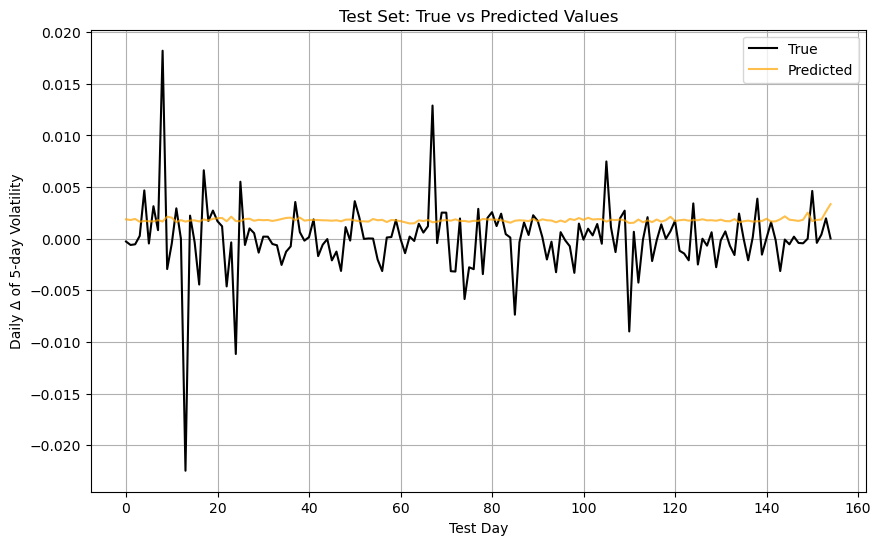

In [119]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(test_labels, label='True', color='black')
plt.plot(test_preds, label='Predicted', color='orange', alpha=0.7)
plt.xlabel("Test Day")
plt.ylabel("Daily Δ of 5-day Volatility")
plt.title("Test Set: True vs Predicted Values")
plt.legend()
plt.grid(True)
plt.show()

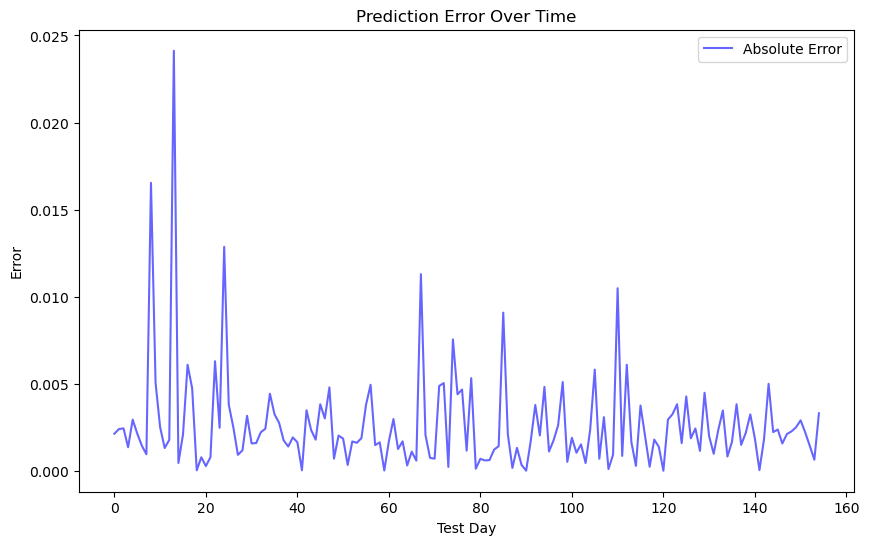

In [120]:
errors = test_labels - test_preds

# Optional: absolute error
abs_errors = np.abs(errors)

plt.figure(figsize=(10, 6))
plt.plot(abs_errors, label='Absolute Error', color='blue', alpha=0.6)

plt.title("Prediction Error Over Time")
plt.xlabel("Test Day")
plt.ylabel("Error")
plt.legend()
plt.show()